# 機械学習の解釈手法 練習ノートブック

『機械学習を解釈する技術』の4手法（**PFI / PD / ICE / SHAP**）を既存ライブラリで再現し、さらに本書の範囲外の手法（**ALE / LIME / 反実仮想説明**）まで一気に試すための練習ノートです。

**設計方針**
- データは**生成過程が既知の合成データ**を使う。本書と同じく「答えが分かっている状況で手法の挙動を確かめる」ためです。特に *experience（経験年数）の効果が is_senior によって符号反転する交互作用* を仕込んであり、これが **PDでは相殺されて消え、ICEで初めて見える** という本書5章の核心を再現します。
- 各手法は「自作せずライブラリで最短で描く」ことを優先。対応表は下記。

| 本書の手法 | このノートで使うライブラリ |
| --- | --- |
| PFI | `sklearn.inspection.permutation_importance` |
| PD / ICE | `sklearn.inspection.PartialDependenceDisplay` |
| SHAP | `shap`（新API） |
| （範囲外）ALE | `PyALE` |
| （範囲外）LIME | `lime` |
| （範囲外）反実仮想 | `dice-ml` |

> 実行順は上から順番でOKです。SHAP以降は独立しているので、必要な節だけ飛ばして実行しても動きます。

## 0. セットアップ

未導入のライブラリがあれば次のセルのコメントを外して実行してください。

In [30]:
!pip install scikit-learn shap PyALE lime dice-ml matplotlib seaborn
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import japanize_matplotlib

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (7, 4)
plt.rcParams["font.size"] = 11
RANDOM_STATE = 42

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 3.9 MB/s eta 0:00:00a 0:00:01
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.5/2.5 MB 4.8 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.2/12.2 MB 6.2 MB/s eta 0:00:0000:0100:01
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283853 sha256=741cc8173f142b510369a8cba917f86cf0ff11ce886690751f2395604c1d8d7c
  Stored in directory: /root/.cache/pip/wheels/e6/a6/20/cc1e293fcdb67ede666fed293cb895395e7ecceb4467779546
Successfully built lime
  Attempting uninstall: pandas
    Found existing installation: pandas 2.0.3
    Uninstalling pandas-2.0.3:
      Successfully uninstalled pandas-2.0.3

[notice] A new release of pip is available: 23.3 -> 25.0.1
[notice] To update, run: pip install --upgrade pip


## 1. 合成データの生成

求人推薦を模したデータです。目的変数は「応募確率」。**生成ルールを人間が知っている**のがポイントです。

| 特徴量 | 意味 | 応募確率への効き方（真の関係） |
| --- | --- | --- |
| `match_score` | スキルマッチ度 (0–1) | 常に**正**。強い |
| `salary_gap` | 希望と提示年収のギャップ（標準化） | 絶対値が大きいほど**負**（ズレは嫌われる） |
| `experience` | 経験年数 (0–20) | **is_senior=1 なら正、is_senior=0 なら負**（★交互作用） |
| `is_senior` | シニア向け求人か (0/1) | それ自体＋上の交互作用のスイッチ |
| `noise_feat` | 無関係なダミー | 効果ゼロ（デバッグの答え合わせ用） |

`experience` の効き方が `is_senior` で逆転するのが仕掛けです。

In [17]:
rng = np.random.default_rng(RANDOM_STATE)
n = 6000

experience  = rng.uniform(0, 20, n)
salary_gap  = rng.normal(0, 1, n)
match_score = rng.uniform(0, 1, n)
is_senior   = rng.integers(0, 2, n)
noise_feat  = rng.normal(0, 1, n)   # 効果ゼロ（重要度が0付近に出るはず）

# 真の生成過程（logit）
logit = (
    2.5 * match_score
    - 1.0 * np.abs(salary_gap)
    + np.where(is_senior == 1, 0.15 * experience, -0.15 * experience)  # ★符号反転
)
apply_prob = 1 / (1 + np.exp(-logit)) + rng.normal(0, 0.05, n)

X = pd.DataFrame({
    "experience": experience,
    "salary_gap": salary_gap,
    "match_score": match_score,
    "is_senior": is_senior,
    "noise_feat": noise_feat,
})
y = pd.Series(apply_prob, name="apply_prob")

display(X.head(), y.head())

,experience,salary_gap,match_score,is_senior,noise_feat
0,15.479121,-1.036994,0.388137,1,0.531216
1,8.777569,0.482635,0.056619,1,-0.633882
2,17.171958,-0.607529,0.408877,0,-1.616777
3,13.947361,-1.649066,0.772282,0,2.113693
4,1.883547,-0.287471,0.197028,0,0.956124


0    0.947536
1    0.645073
2    0.141030
3    0.160792
4    0.432920
Name: apply_prob, dtype: float64

## 2. モデルの学習（Random Forest）

本書と同じく、高精度だが解釈しにくいブラックボックスモデルを用意します。

In [18]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

model = RandomForestRegressor(
    n_estimators=300, max_depth=10, n_jobs=-1, random_state=RANDOM_STATE
)
model.fit(X_train, y_train)

print(f"R^2 (train): {model.score(X_train, y_train):.3f}")
print(f"R^2 (test) : {model.score(X_test, y_test):.3f}")

R^2 (train): 0.985
R^2 (test) : 0.962


高いR²が出ます。**モデルは真の関係（交互作用含む）をきちんと学習できている**、という前提をここで確認しておくのが重要です。以降でPDが平坦になるのは「モデルの失敗」ではなく「PDという可視化の限界」だと切り分けられるからです。

## 3. PFI — Permutation Feature Importance

`permutation_importance` で「どの特徴量が効いているか」を測ります。本書の教えに従い、平均だけでなく**ばらつき（分布）**も見ます。

,feature,importance_mean,importance_std
0,is_senior,1.581119,0.064898
1,experience,0.358318,0.016593
2,match_score,0.255575,0.011198
3,salary_gap,0.150713,0.007072
4,noise_feat,-0.000002,0.000166


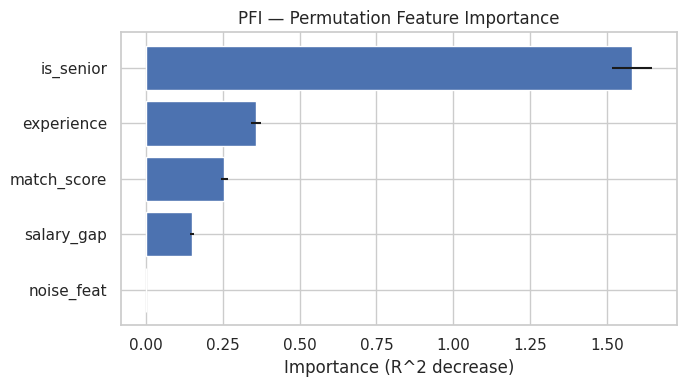

In [19]:
from sklearn.inspection import permutation_importance

pfi = permutation_importance(
    model, X_test, y_test,
    n_repeats=10, random_state=RANDOM_STATE, scoring="r2",
)

pfi_df = (
    pd.DataFrame({
        "feature": X.columns,
        "importance_mean": pfi.importances_mean,
        "importance_std": pfi.importances_std,
    })
    .sort_values("importance_mean", ascending=False)
    .reset_index(drop=True)
)
display(pfi_df)

fig, ax = plt.subplots()
order = pfi_df["feature"][::-1]
ax.barh(order, pfi_df["importance_mean"][::-1],
        xerr=pfi_df["importance_std"][::-1], color="#4C72B0")
ax.set_xlabel("Importance (R^2 decrease)")
ax.set_title("PFI — Permutation Feature Importance")
plt.tight_layout(); plt.show()

**読み方**
- `noise_feat` の重要度がほぼ0 → デバッグの答え合わせ成功。もしこれが高く出たらデータ/前処理のバグを疑う（本書の「最も安全な使い方」）。
- `experience` は重要度が**それなりに高い**。ところが次のPDでは平坦に見えます。この食い違いこそが交互作用のサインです。

> 相関の強い特徴量群がある場合は、まとめてシャッフルする **GPFI** が必要ですが、sklearnに直接の関数はありません。その場合は列をグループ化して自作します。

## 4. PD & ICE — Partial Dependence / Individual Conditional Expectation

`PartialDependenceDisplay` は `kind` を切り替えるだけでPD/ICE/両方を出せます。**同じ計算の「平均する/しない」の違い**がそのまま引数になっています。

まず、仕掛けを埋め込んだ `experience` を見ます。

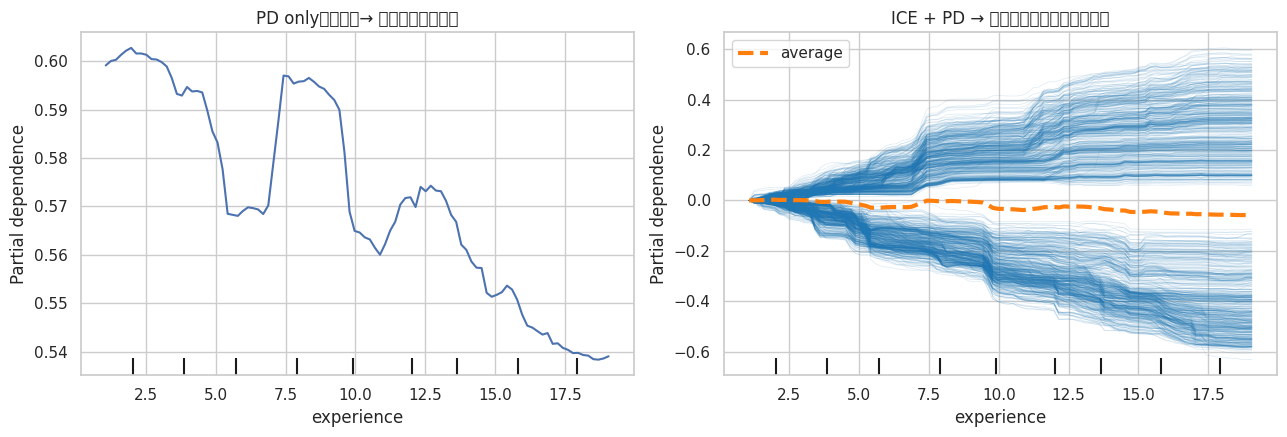

In [20]:
from sklearn.inspection import PartialDependenceDisplay

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# 左: PD のみ（平均線1本）
PartialDependenceDisplay.from_estimator(
    model, X_test, features=["experience"], kind="average", ax=axes[0]
)
axes[0].set_title("PD only（平均）→ ほぼ平坦に見える")

# 右: ICE + PD（centered ICE で起点をそろえる）
PartialDependenceDisplay.from_estimator(
    model, X_test, features=["experience"], kind="both",
    centered=True, ax=axes[1],
    ice_lines_kw={"alpha": 0.15, "color": "tab:blue"},
    pd_line_kw={"color": "tab:orange", "linewidth": 3},
)
axes[1].set_title("ICE + PD → 上がる線と下がる線に分岐")

plt.tight_layout(); plt.show()

**ここが本書5章の核心です。**
- 左のPDは平坦 → 「経験年数は応募に効かない」と誤読しかねない。
- 右のICEを見ると、**右上がりの束と右下がりの束**にくっきり分かれている。これは `is_senior` によって効果が反転しているためで、平均を取るPDでは正負が相殺されて消えていたのです。

**PDが平坦でも、ICEを見るまで「効果なし」と結論してはいけない** — この教訓を体感するためのセルです。

### 4.1 CPD — is_senior で条件付けて平均する

分岐の原因が `is_senior` だと分かったので、その変数で層別してPDを取り直します（本書のCPD＝Conditional PD）。ICEの束を意味あるグループに束ね直すイメージです。

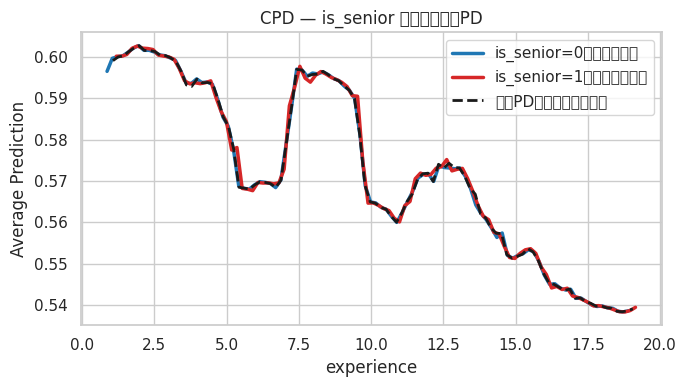

In [21]:
from sklearn.inspection import partial_dependence

def get_pd(mdl, data, feature):
    res = partial_dependence(mdl, data, features=[feature], kind="average")
    grid_key = "grid_values" if "grid_values" in res else "values"
    return np.asarray(res[grid_key][0]), np.asarray(res["average"][0])

fig, ax = plt.subplots()
for sv, label, color in [(0, "is_senior=0（一般求人）", "tab:blue"),
                         (1, "is_senior=1（シニア求人）", "tab:red")]:
    subset = X_test[X_test["is_senior"] == sv]
    gx, gy = get_pd(model, subset, "experience")
    ax.plot(gx, gy, label=label, color=color, linewidth=2.5)

gx_all, gy_all = get_pd(model, X_test, "experience")
ax.plot(gx_all, gy_all, "k--", label="全体PD（相殺され平坦）", linewidth=2)
ax.set(xlabel="experience", ylabel="Average Prediction",
       title="CPD — is_senior で条件付けたPD")
ax.legend(); plt.tight_layout(); plt.show()

層別すると、**シニア求人では右上がり／一般求人では右下がり**という真の関係がはっきり分かれて現れ、全体PD（点線）が両者の中間で平坦になっていた理由が一目で分かります。

### 4.2 素直に効く特徴量も確認

`match_score` は交互作用のない素直な特徴量です。PDとICEがきれいに揃うはずで、対照実験になります。

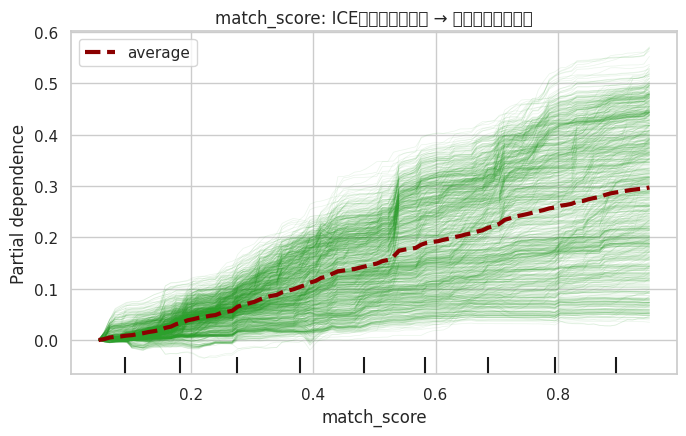

In [22]:
fig, ax = plt.subplots(figsize=(7, 4.5))
PartialDependenceDisplay.from_estimator(
    model, X_test, features=["match_score"], kind="both", centered=True, ax=ax,
    ice_lines_kw={"alpha": 0.1, "color": "tab:green"},
    pd_line_kw={"color": "darkred", "linewidth": 3},
)
ax.set_title("match_score: ICEの束がほぼ平行 → 交互作用が小さい")
plt.tight_layout(); plt.show()

### 4.3 2変数PD（交互作用の可視化）

`experience × is_senior` の2次元PDをヒートマップで見ると、交互作用が面として現れます。

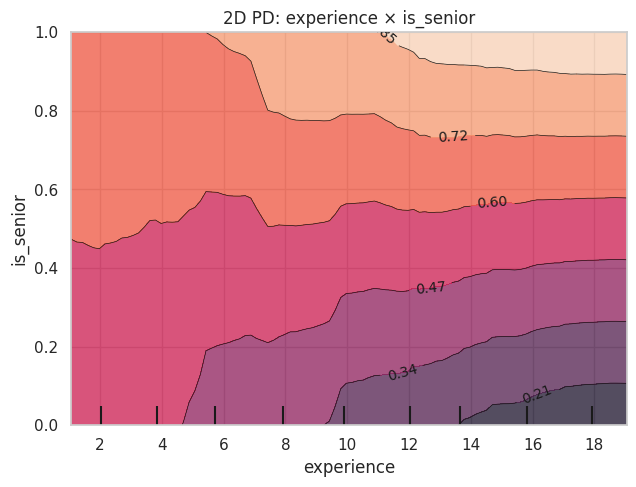

In [23]:
fig, ax = plt.subplots(figsize=(6.5, 5))
PartialDependenceDisplay.from_estimator(
    model, X_test, features=[("experience", "is_senior")], ax=ax
)
ax.set_title("2D PD: experience × is_senior")
plt.tight_layout(); plt.show()

## 5. SHAP — なぜこの予測になったのか

`shap.TreeExplainer` で貢献度を計算し、本書6章の「マクロ → ミクロ」の順に可視化します。

In [24]:
import shap

# 計算コスト対策でテストデータをサンプリング（本書の注意点どおり）
X_shap = X_test.sample(400, random_state=RANDOM_STATE)

explainer = shap.TreeExplainer(model)
shap_values = explainer(X_shap)

print("SHAP values shape:", shap_values.values.shape)

SHAP values shape: (400, 5)


### 5.1 マクロ: 特徴量重要度（bar）

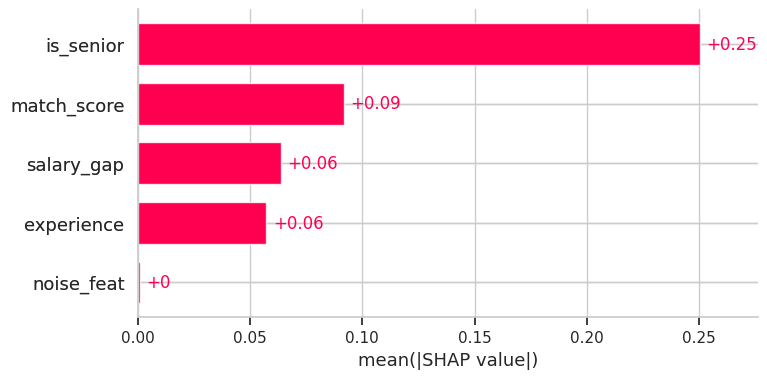

In [25]:
shap.plots.bar(shap_values, show=True)

### 5.2 マクロ: 貢献度の分布（beeswarm）

本書が「**shapは常に分布を確認せよ**」と言っていた図です。点の色が特徴量値の大小を表します。

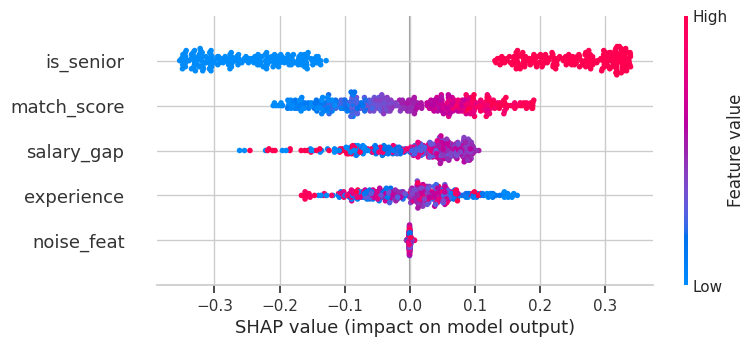

In [26]:
shap.plots.beeswarm(shap_values, show=True)

`experience` の点を見ると、SHAP値が正の側にも負の側にも散らばっているはずです。これは効果が一方向でない＝交互作用の存在を示唆します。PFI（大きさだけ）では見えなかった情報です。

### 5.3 ミクロ: 1インスタンスの予測理由（waterfall）

この応募者への予測値: 0.176


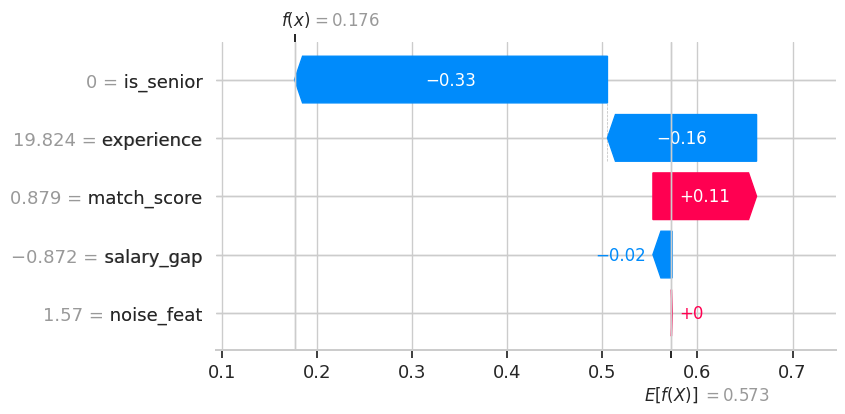

In [27]:
idx = 0
print("この応募者への予測値:", round(float(model.predict(X_shap.iloc[[idx]])[0]), 3))
shap.plots.waterfall(shap_values[idx], show=True)

### 5.4 SHAPをPDのように使う（scatter）

横軸に特徴量値、縦軸にSHAP値を取ると、PD的に関係を見られます。色付けで交互作用も確認できます。

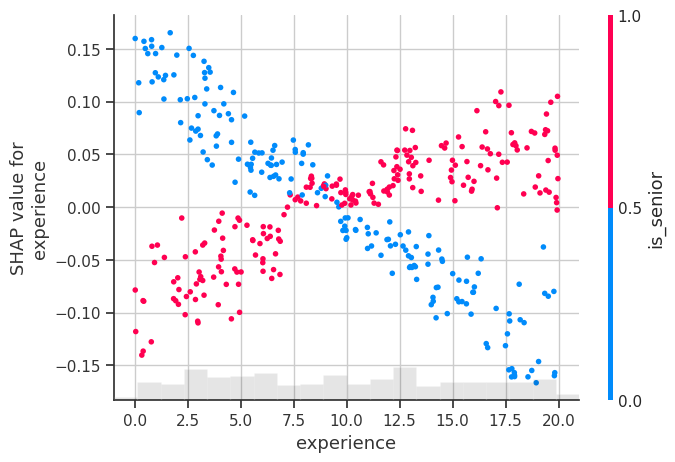

In [28]:
shap.plots.scatter(shap_values[:, "experience"],
                   color=shap_values[:, "is_senior"], show=True)

`is_senior` で色分けすると、`experience` のSHAP値が senior/非senior で逆勾配になり、SHAP上でも交互作用が確認できます。**「なぜ」はSHAP、「もし変えたら」はICE** という補完関係を思い出してください。

## 6.〔範囲外〕ALE — PDの相関・外挿問題への対処

PDは特徴量に相関があると、学習データに存在しない非現実的な組み合わせを作ってしまう弱点がありました。**ALE**は各データ点の近傍だけで効果を積み上げるため、その歪みが出にくい代替手法です。

PyALE._ALE_generic:INFO: Continuous feature detected.


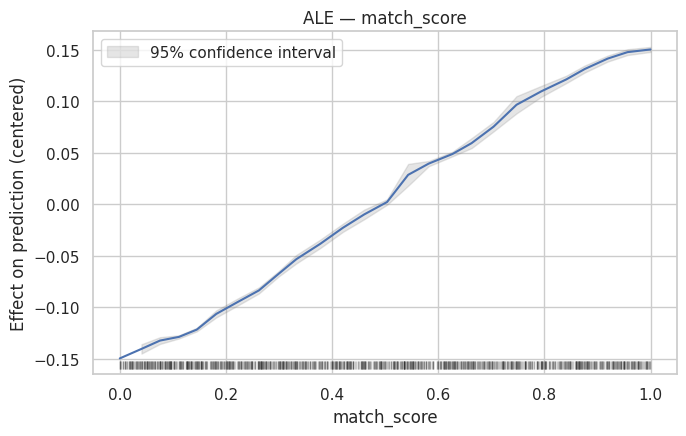

In [31]:
from PyALE import ale

# PyALE は index が連番の DataFrame を想定するので reset_index する
X_test_reset = X_test.reset_index(drop=True)

fig, ax = plt.subplots(figsize=(7, 4.5))
ale_result = ale(
    X=X_test_reset, model=model, feature=["match_score"],
    grid_size=25, include_CI=True, C=0.95, fig=fig, ax=ax,
)
ax.set_title("ALE — match_score")
plt.tight_layout(); plt.show()

ALEの縦軸は「全体平均からの差（中心化された効果）」です。PDと形が近ければPDの結果は信頼でき、大きくズレるなら相関由来の歪みをPDが拾っていた疑いがあります。**求人データは職種・年収・勤務地などが強く相関しがちなので、PDのクロスチェックとしてALEは実用価値が高い**です。

## 7.〔範囲外〕LIME — 局所線形近似による説明

序文で名前だけ登場したLIME。ある1点の周りをシンプルな線形モデルで近似して説明します。SHAPより軽く、セカンドオピニオンになります。

In [32]:
from lime.lime_tabular import LimeTabularExplainer

lime_explainer = LimeTabularExplainer(
    training_data=X_train.values,
    feature_names=list(X.columns),
    mode="regression",
    random_state=RANDOM_STATE,
)

i = 0
exp = lime_explainer.explain_instance(
    data_row=X_test.iloc[i].values,
    predict_fn=model.predict,
    num_features=5,
)
print("対象インスタンスの予測:", round(float(model.predict(X_test.iloc[[i]])[0]), 3))
for feat, weight in exp.as_list():
    print(f"  {feat:35s} {weight:+.4f}")

対象インスタンスの予測: 0.815
  0.00 < is_senior <= 1.00            +0.5006
  -0.02 < salary_gap <= 0.67          +0.0846
  0.26 < match_score <= 0.51          -0.0548
  4.89 < experience <= 9.83           -0.0039
  0.04 < noise_feat <= 0.68           -0.0015


同じインスタンスをSHAP（5.3のwaterfall）とLIMEの両方で説明すると、**手法によって強調される特徴量が微妙に違う**ことがあります。どちらが正解ということではなく、説明の頑健性を確認する使い方が実務的です。

## 8.〔範囲外〕反実仮想説明 — 「何が変われば結果が変わるか」

SHAP/ICEが「なぜ」「もし動かしたら」を答えるのに対し、反実仮想は **「望む結果に必要な最小の変更」** を逆算します。求人推薦で当事者にアクションを提示したい場面に直結します。

In [33]:
import dice_ml

train_df = pd.concat([X_train, y_train], axis=1)

dice_data = dice_ml.Data(
    dataframe=train_df,
    continuous_features=["experience", "salary_gap", "match_score", "noise_feat"],
    outcome_name="apply_prob",
)
dice_model = dice_ml.Model(model=model, backend="sklearn", model_type="regressor")
dice_exp = dice_ml.Dice(dice_data, dice_model, method="random")

# 応募確率が低い応募者を1人選ぶ
preds = model.predict(X_test)
low_idx = int(np.argmin(preds))
query = X_test.iloc[[low_idx]]
print("元の応募確率:", round(float(model.predict(query)[0]), 3))
query

元の応募確率: -0.02


,experience,salary_gap,match_score,is_senior,noise_feat
2653,14.891595,-1.902902,0.117961,0,0.375923


In [34]:
cf = dice_exp.generate_counterfactuals(
    query,
    total_CFs=3,
    desired_range=[0.7, 1.0],                       # 応募確率を0.7以上にしたい
    features_to_vary=["experience", "salary_gap", "match_score"],  # is_seniorは動かさない
)
cf_df = cf.cf_examples_list[0].final_cfs_df
print("反実仮想（この状態なら応募確率が0.7以上になる）:")
cf_df

100%|██████████| 1/1 [00:01<00:00,  1.33s/it]

反実仮想（この状態なら応募確率が0.7以上になる）:


,experience,salary_gap,match_score,is_senior,noise_feat,apply_prob
0,2.711743,-0.136291,0.610028,0,0.375923,1.0
1,1.398733,0.080911,0.878456,0,0.375923,1.0
2,3.467768,-0.383354,0.755507,0,0.375923,1.0


生成された各行は「元の応募者が**この値になっていれば**応募確率が0.7以上になった」という提案です。`match_score` や `salary_gap` がどう変わるべきかが読み取れます。

> **重要な注意（本書のスタンスの継承）**
> これは *モデルの予測を変える最小変更* であって、*現実に介入すれば結果が変わる* という**因果的保証ではありません**。特にあなたの推薦システムには**フィードバックループ**があるため、「この特徴量を上げれば応募が増える」を施策に落とす前に、必ずA/Bテストや因果推論での検証を挟むこと。解釈手法は**仮説構築まで**、が本書の一貫した教えです。

## 9. まとめ — 実務での使い分け

| 目的 | 手法 | このノートの節 |
| --- | --- | --- |
| モデルのデバッグ | PFI → PD | 3, 4 |
| 全体傾向の説明 | PFI, PD | 3, 4 |
| 交互作用の発見 | ICE, CPD, 2D-PD | 4.0–4.3 |
| 個別予測の理由 | SHAP (waterfall) | 5.3 |
| PDの信頼性チェック | ALE | 6 |
| 説明の頑健性確認 | SHAP + LIME | 5, 7 |
| 当事者へのアクション提示 | 反実仮想 (DiCE) | 8 |

**鉄則の再確認**
1. 「予測値との関係」と「目的変数との因果」を言葉で区別する
2. 因果解釈は仮説構築まで。証明はA/Bテスト・因果推論へ
3. PDが平坦でもICEを見るまで「効果なし」と言わない
4. SHAPは平均だけでなく分布（beeswarm）を必ず見る
5. 外挿領域（実測値から離れた点）は解釈しない

---
*次のステップ: 自分の実データ（求人推薦のスコアリングモデル）に差し替え、2チャネルそれぞれでPFIを算出して重要度プロファイルの乖離を見ると、Training/Serving Skewの検知に使えます。*